Epoch 1/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0203 - val_loss: 0.0242
Epoch 2/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0088 - val_loss: 0.0145
Epoch 3/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0068 - val_loss: 0.0111
Epoch 4/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0061 - val_loss: 0.0094
Epoch 5/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0057 - val_loss: 0.0087
Epoch 6/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0055 - val_loss: 0.0085
Epoch 7/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0054 - val_loss: 0.0086
Epoch 8/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0052 - val_loss: 0.0087
Epoch 9/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0052 - val_loss: 0.0085
Epoch 10/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0052 - val_loss: 0.0084
Epoch 11/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0051 - val_loss: 0.0084
Epoch 12/22
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

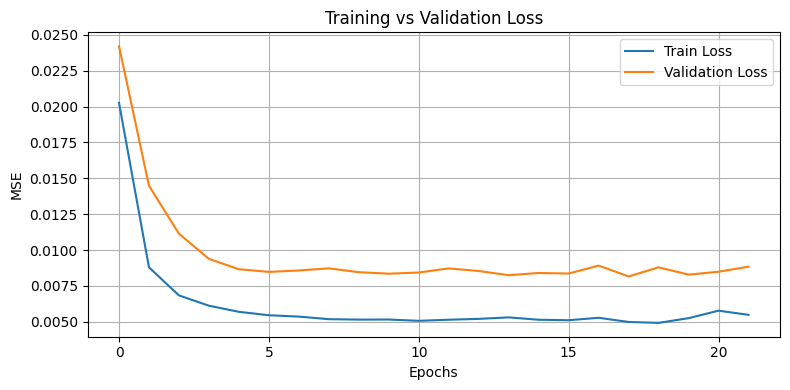

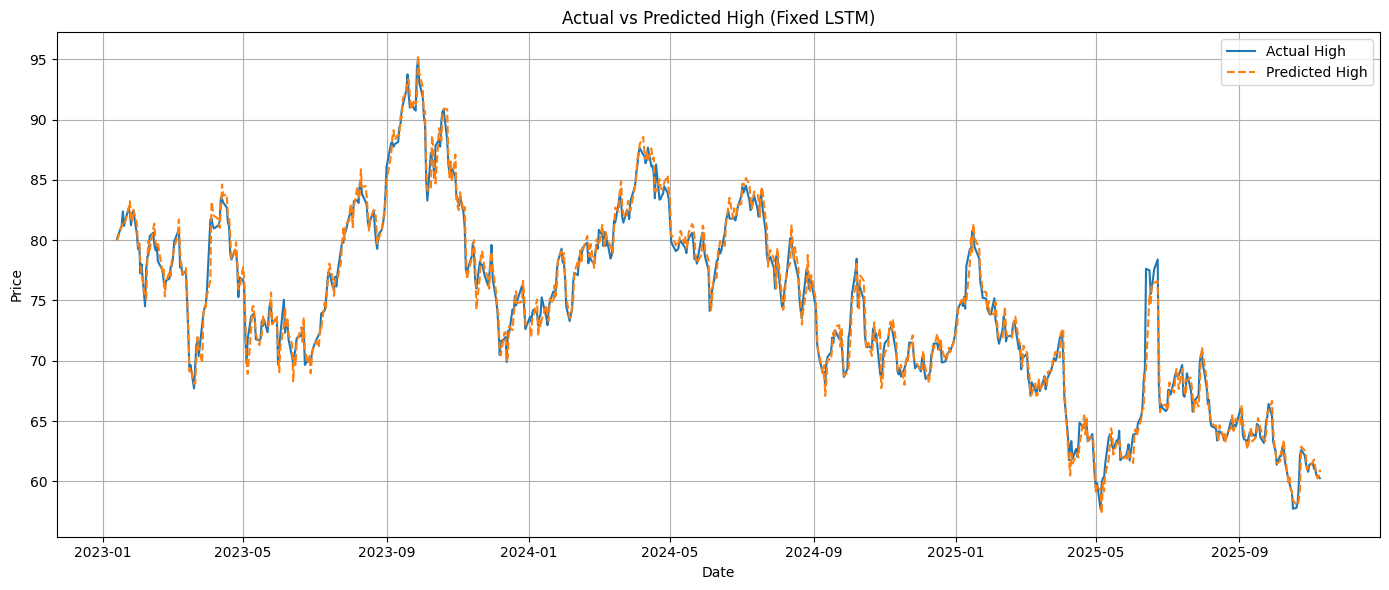

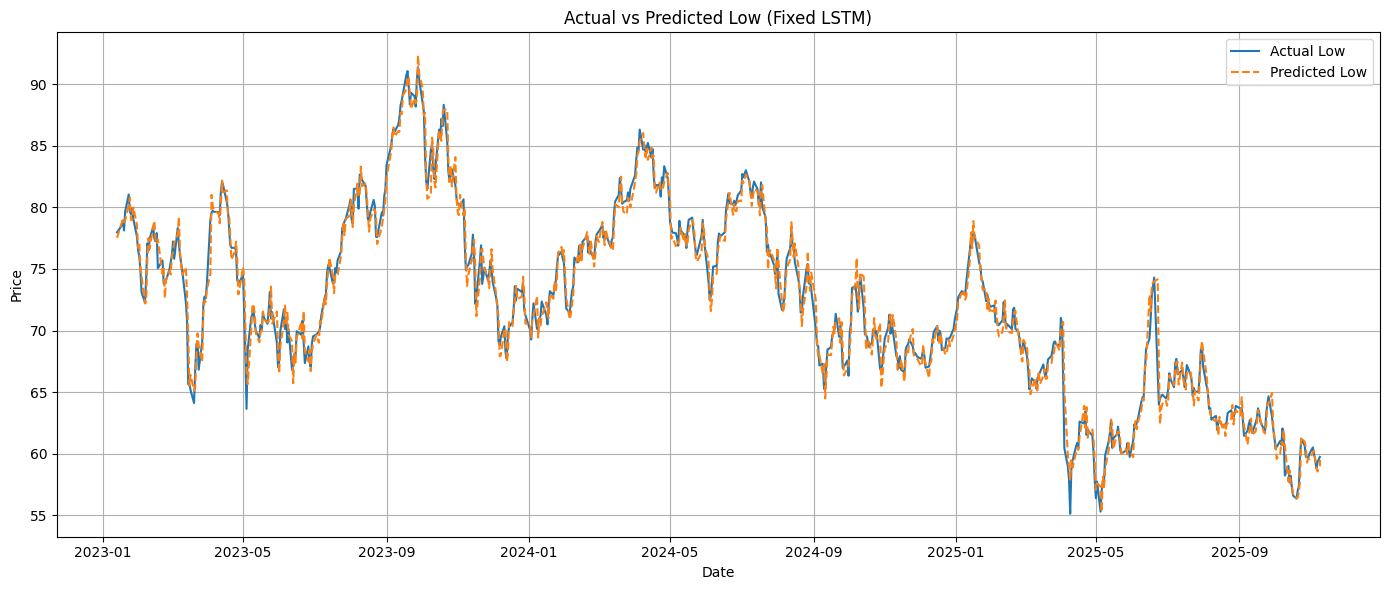

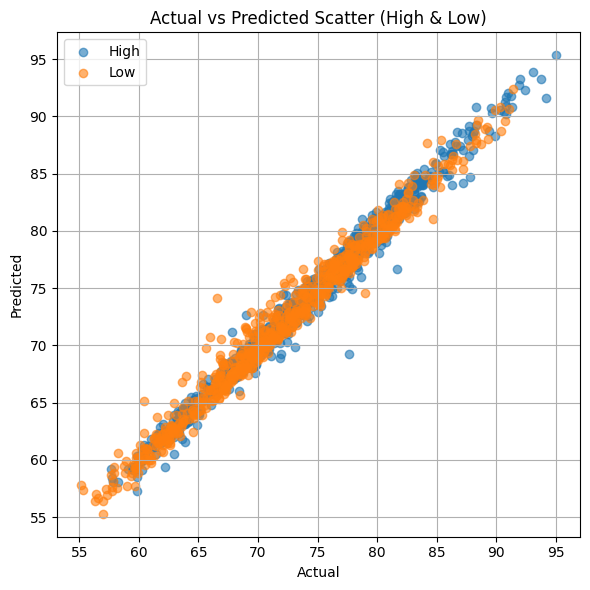

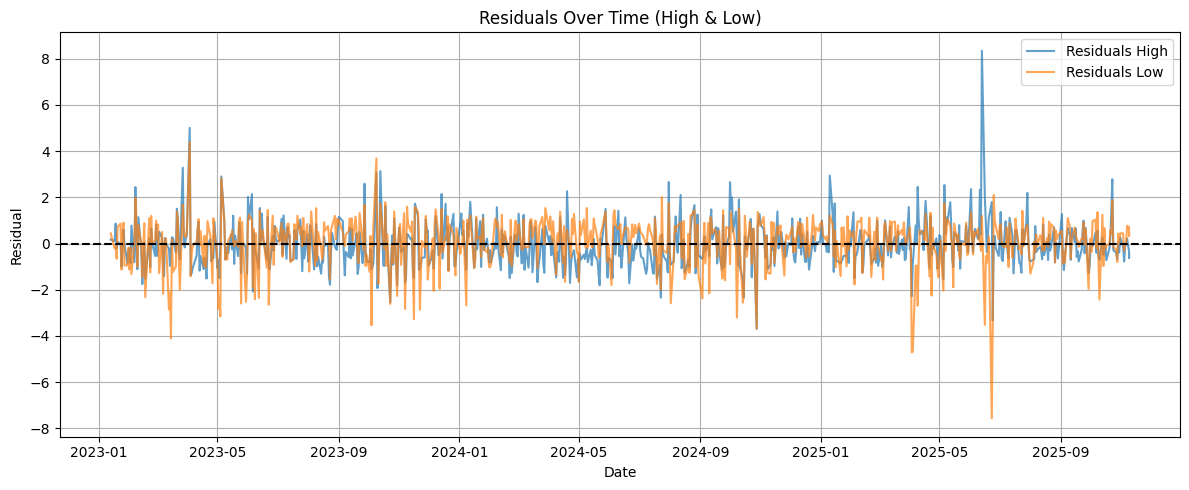

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# ------------------------------
# Setup
# ------------------------------
warnings.filterwarnings("ignore")
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# ------------------------------
# 1) Load & Clean the dataset
# ------------------------------
df = pd.read_csv("crude_oil_2007_to_present.csv")

# Rename first column to Date and ensure datetime type
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Clean numeric columns (remove commas, convert to numeric)
for col in df.columns:
    if col != "Date":
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace(",", "", regex=False)
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort by date and handle missing data
df = df.sort_values("Date").reset_index(drop=True)
df = df.fillna(method="ffill").fillna(method="bfill")

# Keep only relevant columns
cols = [c for c in ["Date", "Open", "High", "Low", "Close"] if c in df.columns]
df = df[cols].dropna().reset_index(drop=True)

# -----------------------------------------
# 2) Feature scaling & sequence preparation
# -----------------------------------------
FEATURES = [c for c in df.columns if c not in ["Date"]]
TARGETS = ["High", "Low"]

X_raw = df[FEATURES].values
y_raw = df[TARGETS].values

scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_raw)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y_raw)

def make_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

# -----------------------------------------
# 3) Train/Val/Test split (time-ordered)
# -----------------------------------------
n = len(X_scaled)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

X_train_raw, y_train_raw = X_scaled[:train_end], y_scaled[:train_end]
X_val_raw,   y_val_raw   = X_scaled[train_end:val_end], y_scaled[train_end:val_end]
X_test_raw,  y_test_raw  = X_scaled[val_end:], y_scaled[val_end:]
dates_test = df["Date"].values[val_end:]

# -----------------------------------------
# 4) Fixed Hyperparameters from ARO
# -----------------------------------------
seq_len = 30
units   = 160.0
dropout = 0.005093563216636045
lr      = 0.002939598205532339
batch_sz= 16
epochs  = int(22.114677099344227)

# -----------------------------------------
# 5) Build LSTM model
# -----------------------------------------
def build_lstm(seq_len, n_features, units, dropout, lr):
    model = Sequential()
    model.add(LSTM(int(units), activation='tanh', input_shape=(seq_len, n_features)))
    if dropout > 0:
        model.add(Dropout(dropout))
    model.add(Dense(y_scaled.shape[1]))  # 2 outputs: High & Low
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

# -----------------------------------------
# 6) Prepare data & Train model
# -----------------------------------------
X_trval_raw = np.vstack([X_train_raw, X_val_raw])
y_trval_raw = np.vstack([y_train_raw, y_val_raw])

X_trval, y_trval = make_sequences(X_trval_raw, y_trval_raw, seq_len)
X_test,  y_test  = make_sequences(np.vstack([X_trval_raw[-seq_len:], X_test_raw]),
                                  np.vstack([y_trval_raw[-seq_len:], y_test_raw]),
                                  seq_len)

model = build_lstm(seq_len, X_trval.shape[2], units, dropout, lr)
cb = [EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)]

history = model.fit(
    X_trval, y_trval,
    validation_split=0.1,
    epochs=epochs,
    batch_size=batch_sz,
    callbacks=cb,
    verbose=1
)

# -----------------------------------------
# 7) Predictions & Evaluation
# -----------------------------------------
y_pred_scaled = model.predict(X_test, verbose=0)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = scaler_y.inverse_transform(y_test)

def compute_metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
    print(f"{label} -> MAE: {mae:.2f} | RMSE: {rmse:.2f} | R²: {r2:.3f} | MAPE: {mape:.2f}%")
    return mae, rmse, r2, mape

print("\n=== Test Metrics (Fixed Hyperparameter LSTM) ===")
_ = compute_metrics(y_true[:,0], y_pred[:,0], "High")
_ = compute_metrics(y_true[:,1], y_pred[:,1], "Low")

# -----------------------------------------
# 8) Visualizations (Fixed)
# -----------------------------------------
# Align dates properly for sequences
total_test_len = len(y_true)
plot_dates = dates_test[-total_test_len:]

# Training vs Validation Loss
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs'); plt.ylabel('MSE'); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

# Actual vs Predicted High
plt.figure(figsize=(14,6))
plt.plot(plot_dates, y_true[:,0], label="Actual High")
plt.plot(plot_dates, y_pred[:,0], label="Predicted High", linestyle="--")
plt.title("Actual vs Predicted High (Fixed LSTM)")
plt.xlabel("Date"); plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()

# Actual vs Predicted Low
plt.figure(figsize=(14,6))
plt.plot(plot_dates, y_true[:,1], label="Actual Low")
plt.plot(plot_dates, y_pred[:,1], label="Predicted Low", linestyle="--")
plt.title("Actual vs Predicted Low (Fixed LSTM)")
plt.xlabel("Date"); plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()

# Scatter Plot (High & Low)
plt.figure(figsize=(6,6))
plt.scatter(y_true[:,0], y_pred[:,0], alpha=0.6, label="High")
plt.scatter(y_true[:,1], y_pred[:,1], alpha=0.6, label="Low")
plt.title("Actual vs Predicted Scatter (High & Low)")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()

# Residual Plot (Optional Diagnostic)
residuals_high = y_true[:,0] - y_pred[:,0]
residuals_low  = y_true[:,1] - y_pred[:,1]

plt.figure(figsize=(12,5))
plt.plot(plot_dates, residuals_high, label="Residuals High", alpha=0.7)
plt.plot(plot_dates, residuals_low, label="Residuals Low", alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals Over Time (High & Low)")
plt.xlabel("Date"); plt.ylabel("Residual")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()
